# Routing results: plots from your CSV and JSON files
Set RUN_DIR in the first code cell, then Run All. No GPU required.
Reads routing-summary.csv and routing-report.json from analyze.py.
Figures export to RUN_DIR/figures as PNG, SVG and PDF.

Routing costs are replay estimates from measured GPU requests, excluding router CPU
energy and live-serving overhead. Oracle is hindsight, not deployable. Workload
mixtures reweight the same test questions. Bootstrap intervals are conditional on
the fitted router and do not measure repeated-run variability.


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (11, 6.2), 'figure.dpi': 120,
    'font.size': 13, 'axes.titlesize': 19, 'axes.labelsize': 14,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans', 'savefig.facecolor': 'white',
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
})
BLUE, TEAL, ORANGE, GREY = '#315A9E', '#00897B', '#C97822', '#777777'
# FOOT = '300 held-out questions | B200, BF16, batch=1 | Routing costs: replay estimates; GPU energy only'
# def finish(fig, name, note=FOOT):
#     fig.text(.08, .025, note, fontsize=9, color='#555555')
#     fig.tight_layout(rect=(0, .075, 1, .86 if name == '01_main_result' else .96))
#     for ext in ['png', 'svg', 'pdf']:
#         fig.savefig(OUT / f'{name}.{ext}', dpi=300)
#     plt.show()

# Change ONLY this path to point to the results directory on this machine.
RUN_DIR = Path('/vast/home/e/eli22/efficient-ai/screen-results/collect-9251129')
# Local example after downloading the results folder:
# RUN_DIR = Path.home() / 'Downloads' / 'collect-9251129'

import csv
import json

summary_file = RUN_DIR / 'routing-summary.csv'
report_file = RUN_DIR / 'routing-report.json'
for path in [summary_file, report_file]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}. Set RUN_DIR to your results folder. Kernel cwd: {Path.cwd()}')
with summary_file.open(newline='') as f:
    summary = list(csv.DictReader(f))
with report_file.open() as f:
    report = json.load(f)

def get_row(workload, policy):
    matches = [r for r in summary if r['workload']==workload and r['policy']==policy]
    if len(matches)!=1:
        raise ValueError(f'Expected one row for {workload}/{policy}; found {len(matches)}')
    return matches[0]

def number(row, name):
    value = float(row[name])
    if not np.isfinite(value):
        raise ValueError(f'Nonfinite {name}: {row}')
    return value

policies = ['always_small', 'always_large', 'learned_router',
            'random_same_expected_small_fraction', 'oracle_hindsight']
labels = ['Always 1.7B', 'Always 8B', 'Learned router', 'Random router']
balanced = [get_row('balanced', policy) for policy in policies]
accuracy = np.array([number(r, 'accuracy') * 100 for r in balanced])
energy = np.array([number(r, 'gpu_joules') for r in balanced])
latency = np.array([number(r, 'seconds') for r in balanced])
colors = [GREY, BLUE, TEAL, GREY, ORANGE]
router_cpu_seconds = number(balanced[2], 'router_cpu_seconds_per_request')
energy_savings = number(balanced[2], 'gpu_energy_savings_fraction') * 100
accuracy_gap = number(balanced[2], 'accuracy_gap_vs_large') * 100
OUT = RUN_DIR / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
print('Read:', summary_file, report_file, sep='\n')
print(f'Validation-selected threshold: {report["selected_threshold"]}')
print(f'Router small-model fraction: {report["test_small_fraction"]:.1%}')
print(f'Learned router: {energy_savings:.1f}% energy savings; {accuracy_gap:.2f} percentage-point accuracy change.')
print('Figures will be saved to:', OUT)


Read:
/vast/home/e/eli22/efficient-ai/screen-results/collect-9251129/routing-summary.csv
/vast/home/e/eli22/efficient-ai/screen-results/collect-9251129/routing-report.json
Validation-selected threshold: 0.8
Router small-model fraction: 29.3%
Learned router: 11.6% energy savings; -2.33 percentage-point accuracy change.
Figures will be saved to: /vast/home/e/eli22/efficient-ai/screen-results/collect-9251129/figures


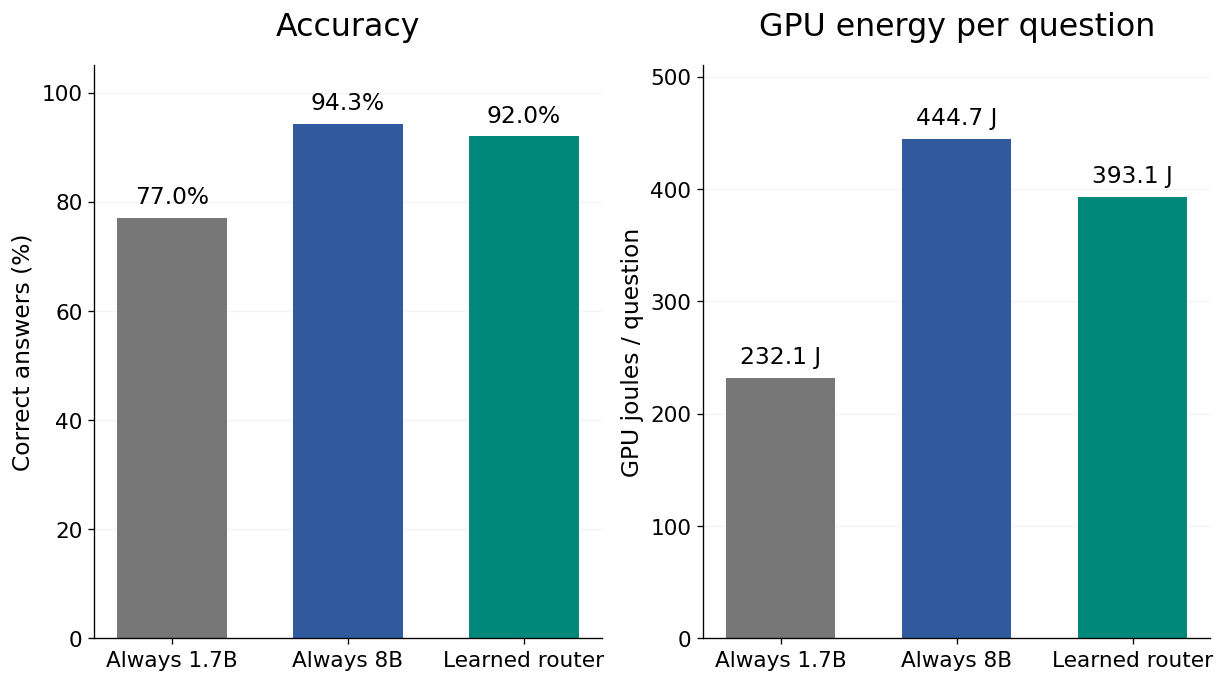

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
idx = [0, 1, 2]
x = np.arange(3)
for ax, values, title, ylabel, limit in [
    (axes[0], accuracy[idx], 'Accuracy', 'Correct answers (%)', 105),
    (axes[1], energy[idx], 'GPU energy per question', 'GPU joules / question', 510),
]:
    ax.bar(x, values, color=[colors[i] for i in idx], width=.62)
    ax.set_xticks(x, [labels[i] for i in idx])
    ax.set_ylim(0, limit)
    ax.set_title(title, pad=18)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    for i, value in enumerate(values):
        ax.text(i, value+limit*.025, f'{value:.1f}' + ('%' if ax is axes[0] else ' J'), ha='center', fontsize=14)


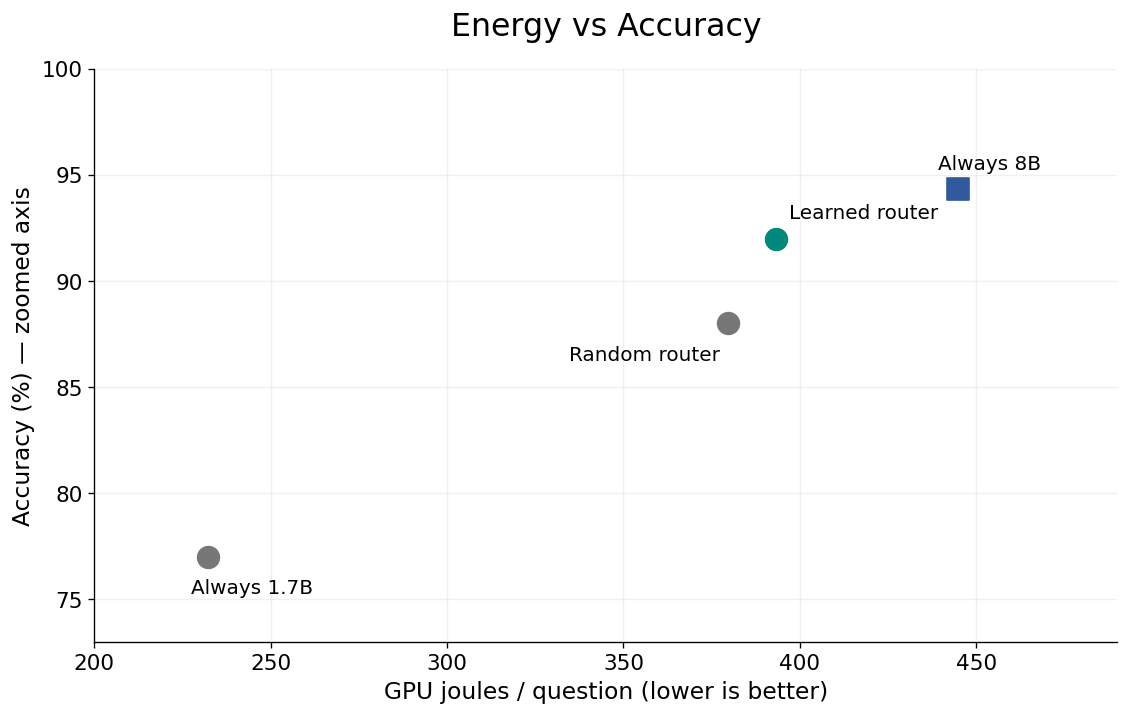

In [ ]:
fig, ax = plt.subplots()
for i, label in enumerate(labels):
    ax.scatter(energy[i], accuracy[i], s=170, color=colors[i],
               marker='*' if i==4 else ('s' if i==1 else 'o'), zorder=3)
    offsets = [(-10, -22), (-12, 12), (8, 12), (-95, -22), (12, 8)]
    ax.annotate(label, (energy[i], accuracy[i]), xytext=offsets[i],
                textcoords='offset points', fontsize=12)
ax.set_xlim(200, 490)
ax.set_ylim(73, 100)
ax.set_xlabel('GPU joules / question ')
ax.set_ylabel('Accuracy (%) — zoomed axis')
ax.set_title('Energy vs Accuracy', pad=20)
ax.grid(alpha=.18)


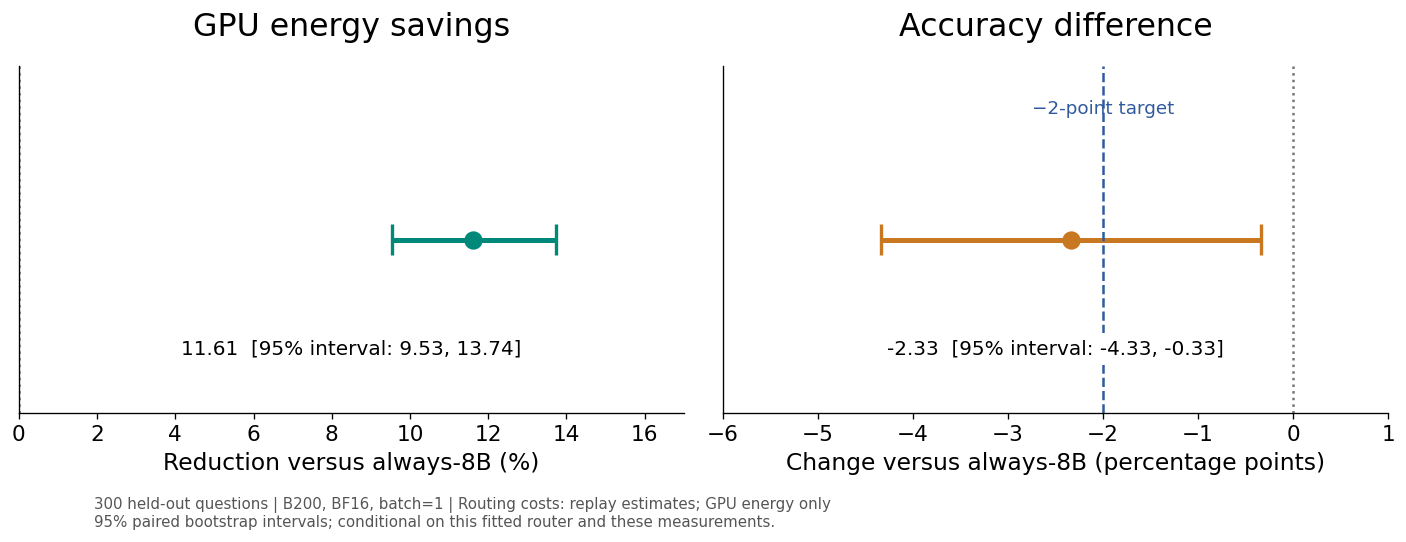

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ci = report['balanced_test_bootstrap_95']
energy_lo, energy_hi = np.array(ci['gpu_energy_savings_fraction']) * 100
accuracy_lo, accuracy_hi = np.array(ci['accuracy_gap_vs_large']) * 100
intervals = [
    (energy_savings, energy_lo, energy_hi, TEAL,
     'GPU energy savings', 'Reduction versus always-8B (%)', (0, 17)),
    (accuracy_gap, accuracy_lo, accuracy_hi, ORANGE,
     'Accuracy difference', 'Change versus always-8B (percentage points)', (-6, 1)),
]
for ax, (point, lo, hi, color, title, xlabel, limits) in zip(axes, intervals):
    ax.hlines(0, lo, hi, color=color, linewidth=3)
    ax.vlines([lo, hi], -.07, .07, color=color, linewidth=2)
    ax.plot(point, 0, 'o', color=color, markersize=10)
    ax.axvline(0, color=GREY, ls=':', lw=1.5)
    ax.set_xlim(min(limits[0], lo-1), max(limits[1], hi+1))
    ax.set_ylim(-.8, .8)
    ax.set_yticks([])
    ax.set_title(title, pad=18)
    ax.set_xlabel(xlabel)
    ax.text(.5, .17, f'{point:.2f}  [95% interval: {lo:.2f}, {hi:.2f}]',
            transform=ax.transAxes, ha='center', fontsize=12, bbox=dict(facecolor='white', edgecolor='none', pad=4))
tolerance_pp = float(report['tolerance']) * 100
axes[1].axvline(-tolerance_pp, color=BLUE, ls='--', lw=1.5)
axes[1].text(-tolerance_pp, .58, f'−{tolerance_pp:g}-point target', color=BLUE, ha='center', fontsize=11)
finish(fig, '04_bootstrap_intervals', FOOT + '\n95% paired bootstrap intervals; conditional on this fitted router and these measurements.')


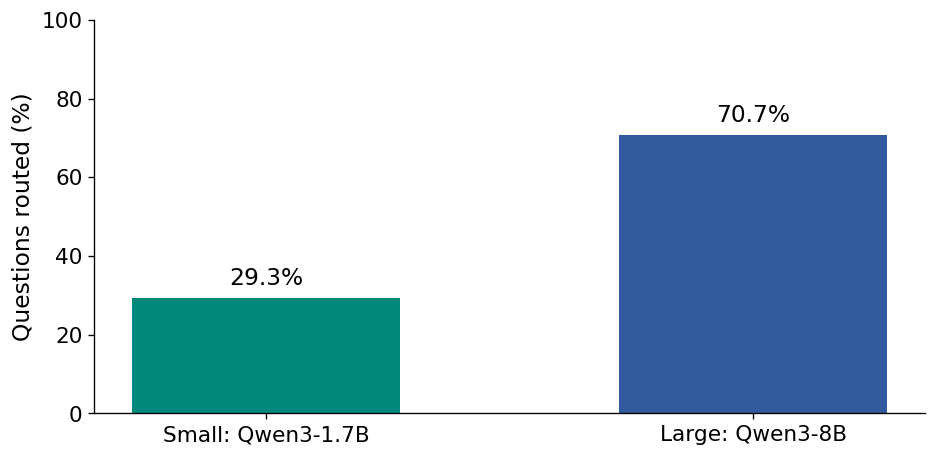

In [4]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

with (RUN_DIR / "routing-report.json").open() as f:
    report = json.load(f)

small_pct = report["test_small_fraction"] * 100
big_pct = 100 - small_pct

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    ["Small: Qwen3-1.7B", "Large: Qwen3-8B"],
    [small_pct, big_pct],
    color=["#00897B", "#315A9E"],
    width=0.55,
)

ax.bar_label(bars, fmt="%.1f%%", padding=5, fontsize=14)
ax.set_ylabel("Questions routed (%)")
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(RUN_DIR / "learned_router_split.png", dpi=300)
plt.show()